# EDA — Camada Silver
**Projeto:** analise-importacoes-brasil  
**Fonte:** Receita Federal do Brasil — Estatísticas de Declarações de Importação  

Este notebook:
1. Conecta ao S3 e baixa os Parquets da camada silver para memória local
2. Executa as checagens de qualidade definidas para a silver
3. Apresenta 4 gráficos de EDA para início da exploração

---
## 0. Dependências e configuração

In [1]:
# pip install boto3 pyyaml pandas pyarrow matplotlib seaborn awswrangler

import io
import re
import warnings
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from botocore.exceptions import BotoCoreError, ClientError

warnings.filterwarnings('ignore')

# Estilo dos gráficos
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 130, 'figure.figsize': (12, 5)})

print('Dependências carregadas com sucesso.')

Dependências carregadas com sucesso.


In [3]:
# Carrega configurações do projeto
# Ajuste o caminho caso o notebook não esteja na raiz do repositório
CONFIG_PATH = Path("../../config.yaml")

with open(CONFIG_PATH, encoding='utf-8') as f:
    cfg = yaml.safe_load(f)

BUCKET         = cfg['aws']['bucket']
PREFIXO_SILVER = cfg['s3']['silver']
PERFIL_IAM     = cfg['aws']['profile']
REGIAO         = cfg['aws']['regiao']

print(f'Bucket  : {BUCKET}')
print(f'Prefixo : {PREFIXO_SILVER}')
print(f'Perfil  : {PERFIL_IAM}')

Bucket  : importacoes-brasil-bucket
Prefixo : silver/estatisticas_di/
Perfil  : estatisticas_di


---
## 1. Conexão ao S3 e download da silver

In [4]:
def criar_cliente_s3(perfil: str, regiao: str) -> boto3.client:
    session = boto3.Session(profile_name=perfil, region_name=regiao)
    return session.client('s3')


def listar_parquets_silver(cliente, bucket: str, prefixo: str) -> list[dict]:
    """Lista todos os Parquets na camada silver, com ano_mes extraído da partição."""
    itens = []
    paginator = cliente.get_paginator('list_objects_v2')
    for page in paginator.paginate(Bucket=bucket, Prefix=prefixo):
        for obj in page.get('Contents', []):
            chave = obj['Key']
            if not chave.endswith('.parquet'):
                continue
            match = re.search(r'ano_mes=(\d{4}-\d{2})', chave)
            itens.append({
                'chave'  : chave,
                'nome'   : Path(chave).name,
                'ano_mes': match.group(1) if match else None,
                'tamanho': obj['Size'],
            })
    return sorted(itens, key=lambda x: x['ano_mes'] or '')


def baixar_parquet(cliente, bucket: str, chave: str) -> pd.DataFrame:
    """Baixa um Parquet do S3 diretamente para um DataFrame em memória."""
    response = cliente.get_object(Bucket=bucket, Key=chave)
    return pd.read_parquet(io.BytesIO(response['Body'].read()))


# Conecta e lista
try:
    cliente = criar_cliente_s3(PERFIL_IAM, REGIAO)
    cliente.head_bucket(Bucket=BUCKET)
    print(f'Conexão com o bucket "{BUCKET}" estabelecida.')
except ClientError as e:
    print(f'Erro ao conectar: {e}')
    raise

itens = listar_parquets_silver(cliente, BUCKET, PREFIXO_SILVER)
print(f'\nArquivos encontrados na silver: {len(itens)}')

resumo = pd.DataFrame(itens)
resumo['tamanho_kb'] = (resumo['tamanho'] / 1024).round(1)
print(f'Tamanho total: {resumo["tamanho_kb"].sum():.1f} KB')
resumo[['ano_mes', 'nome', 'tamanho_kb']]

Conexão com o bucket "importacoes-brasil-bucket" estabelecida.

Arquivos encontrados na silver: 64
Tamanho total: 75289.8 KB


,ano_mes,nome,tamanho_kb
0,2021-01,estatisticas_di_2021_01.parquet,1127.8
1,2021-02,estatisticas_di_2021_02.parquet,1107.8
2,2021-03,estatisticas_di_2021_03.parquet,1211.4
3,2021-05,estatisticas_di_2021_05.parquet,1176.0
4,2021-06,estatisticas_di_2021_06.parquet,1154.5
...,...,...,...
59,2026-04,estatisticas_di_2026_04.parquet,929.8
60,2026-05,estatisticas_di_2026_05.parquet,543.2
61,2026-06,estatisticas_di_2026_06.parquet,489.3
62,2026-07,estatisticas_di_2026_07.parquet,469.6


In [5]:
# Download de todos os arquivos e empilhamento em um único DataFrame
# Com arquivos de ~1 MB cada, a série completa cabe facilmente em memória local.

frames = []
for item in itens:
    df_mes = baixar_parquet(cliente, BUCKET, item['chave'])
    frames.append(df_mes)
    print(f"  {item['ano_mes']} — {len(df_mes):,} linhas")

df = pd.concat(frames, ignore_index=True)
print(f'\nDataFrame consolidado: {df.shape[0]:,} linhas × {df.shape[1]} colunas')

  2021-01 — 15,231 linhas
  2021-02 — 14,869 linhas
  2021-03 — 16,731 linhas
  2021-05 — 16,131 linhas
  2021-06 — 15,808 linhas
  2021-07 — 15,844 linhas
  2021-08 — 16,200 linhas
  2021-09 — 16,294 linhas
  2021-10 — 15,810 linhas
  2021-11 — 16,027 linhas
  2021-12 — 15,722 linhas
  2022-01 — 15,333 linhas
  2022-02 — 15,064 linhas
  2022-03 — 16,388 linhas
  2022-04 — 15,192 linhas
  2022-08 — 17,677 linhas
  2022-09 — 16,964 linhas
  2022-10 — 16,831 linhas
  2022-11 — 16,977 linhas
  2022-12 — 16,222 linhas
  2023-01 — 16,518 linhas
  2023-02 — 15,320 linhas
  2023-03 — 17,267 linhas
  2023-04 — 16,110 linhas
  2023-05 — 17,515 linhas
  2023-06 — 16,968 linhas
  2023-07 — 17,127 linhas
  2023-08 — 17,656 linhas
  2023-09 — 17,060 linhas
  2023-10 — 17,035 linhas
  2023-11 — 16,470 linhas
  2023-12 — 16,734 linhas
  2024-01 — 22,374 linhas
  2024-02 — 16,820 linhas
  2024-03 — 16,922 linhas
  2024-04 — 17,994 linhas
  2024-05 — 17,380 linhas
  2024-06 — 17,064 linhas
  2024-07 — 

---
## 2. Checagens de qualidade da camada silver

In [6]:
# ── Checagens de schema ──────────────────────────────────────────────────────

erros  = []
avisos = []

COLUNAS_OBRIGATORIAS = cfg['esquema']['colunas_obrigatorias']
CHAVE_UNICA          = cfg['esquema']['chave_unica']
NCM_TAMANHO          = cfg['esquema']['ncm_tamanho']
PADRAO_ANO_MES       = re.compile(r'^\d{4}-\d{2}$')

# 1. Colunas obrigatórias
faltando = [c for c in COLUNAS_OBRIGATORIAS if c not in df.columns]
if faltando:
    erros.append(f'Colunas obrigatórias ausentes: {faltando}')
else:
    print('✅ Colunas obrigatórias: todas presentes')

# 2. Formato ano_mes
anos_invalidos = df['ano_mes'].dropna()[~df['ano_mes'].dropna().str.match(PADRAO_ANO_MES)].unique()
if len(anos_invalidos) > 0:
    erros.append(f'ano_mes com formato inválido: {anos_invalidos}')
else:
    print('✅ Formato ano_mes: válido')

# 3. Chave única
chave_presente = [c for c in CHAVE_UNICA if c in df.columns]
duplicatas = df.duplicated(subset=chave_presente).sum()
if duplicatas > 0:
    erros.append(f'Chave única violada: {duplicatas:,} linha(s) duplicada(s)')
else:
    print(f'✅ Chave única ({chave_presente}): sem duplicatas')

# 4. NCM com 8 dígitos
ncm_invalido = (df['ncm'].str.len() != NCM_TAMANHO).sum()
if ncm_invalido > 0:
    erros.append(f'NCMs com tamanho != {NCM_TAMANHO}: {ncm_invalido:,} linha(s)')
else:
    print(f'✅ NCM: todos com {NCM_TAMANHO} dígitos')

✅ Colunas obrigatórias: todas presentes
✅ Formato ano_mes: válido
✅ Chave única (['ano_mes', 'ncm', 'nves', 'pais_origem']): sem duplicatas
✅ NCM: todos com 8 dígitos


In [7]:
# ── Checagens de negócio ─────────────────────────────────────────────────────

def checar_min_max(df, col_min, col_max, label):
    v = (df[col_min] > df[col_max]).sum()
    if v > 0:
        erros.append(f'{label}: {col_min} > {col_max} em {v:,} linha(s)')
    else:
        print(f'✅ {label}: min <= max')

checar_min_max(df, 'fob_kg_minimo_dolar_truncado',  'fob_kg_maximo_dolar_truncado',  'FOB/kg')
checar_min_max(df, 'fob_ume_minimo_dolar_truncado', 'fob_ume_maximo_dolar_truncado', 'FOB/UME')
checar_min_max(df, 'frete_minimo_dolar_truncado',   'frete_maximo_dolar_truncado',   'Frete')

# Quartil1 <= Quartil3
v = (df['fob_kg_quartil1_truncado'] > df['fob_kg_quartil3_truncado']).sum()
if v > 0:
    erros.append(f'FOB/kg Q1 > Q3: {v:,} linha(s)')
else:
    print('✅ FOB/kg: Q1 <= Q3')

# Mediana entre Q1 e Q3 (aviso — truncamento pode causar pequenas violações)
med = df['fob_kg_mediana_dolar_truncado']
q1  = df['fob_kg_quartil1_truncado']
q3  = df['fob_kg_quartil3_truncado']
v   = ((med < q1) | (med > q3)).sum()
if v > 0:
    avisos.append(f'FOB/kg mediana fora de [Q1,Q3]: {v:,} linha(s) (efeito do truncamento)')
else:
    print('✅ FOB/kg: mediana dentro de [Q1, Q3]')

# Somas positivas
for col in ['vmle_soma_dolar_truncado', 'peso_liq_soma_truncado', 'qtd_ume_soma_truncado']:
    v = (df[col] <= 0).sum()
    if v > 0:
        erros.append(f'{col} <= 0: {v:,} linha(s)')
    else:
        print(f'✅ {col}: todos > 0')

# UME vazio
ume_vazio = (df['ume'].str.strip() == '').sum()
if ume_vazio > 0:
    avisos.append(f'UME vazio: {ume_vazio:,} linha(s) — esperado "NÃO INFORMADO" na silver')
else:
    print('✅ UME: sem valores vazios')

# Seguro zero (informativo)
seg_zero = (df['seguro_minimo_dolar_truncado'] == 0).sum()
pct_seg  = seg_zero / len(df) * 100
print(f'ℹ️  Seguro mínimo = 0: {seg_zero:,} linha(s) ({pct_seg:.1f}%) — comportamento esperado')

✅ FOB/kg: min <= max
✅ FOB/UME: min <= max
✅ Frete: min <= max
✅ FOB/kg: Q1 <= Q3
✅ vmle_soma_dolar_truncado: todos > 0
✅ peso_liq_soma_truncado: todos > 0
✅ qtd_ume_soma_truncado: todos > 0
✅ UME: sem valores vazios
ℹ️  Seguro mínimo = 0: 964,536 linha(s) (93.7%) — comportamento esperado


In [8]:
# ── Relatório final da qualidade ─────────────────────────────────────────────

print('=' * 55)
print('RELATÓRIO DE QUALIDADE — CAMADA SILVER')
print('=' * 55)

if erros:
    print(f'\n❌ ERROS ({len(erros)}):')
    for e in erros:
        print(f'   • {e}')
else:
    print('\n✅ Nenhum erro encontrado.')

if avisos:
    print(f'\n⚠️  AVISOS ({len(avisos)}):')
    for a in avisos:
        print(f'   • {a}')
else:
    print('✅ Nenhum aviso.')

print('\n' + '=' * 55)
if not erros:
    print('✅ Dados aprovados para análise.')
else:
    print('❌ Corrija os erros antes de prosseguir com a análise.')

RELATÓRIO DE QUALIDADE — CAMADA SILVER

✅ Nenhum erro encontrado.

⚠️  AVISOS (1):
   • FOB/kg mediana fora de [Q1,Q3]: 1 linha(s) (efeito do truncamento)

✅ Dados aprovados para análise.


---
## 3. Preparação para EDA

In [9]:
# Visão geral do DataFrame
print(f'Período coberto : {df["ano_mes"].min()} → {df["ano_mes"].max()}')
print(f'Meses           : {df["ano_mes"].nunique()}')
print(f'Linhas          : {len(df):,}')
print(f'NCMs únicos     : {df["ncm"].nunique():,}')
print(f'Países únicos   : {df["pais_origem"].nunique()}')
print(f'Capítulos NCM   : {df["capitulo_ncm"].nunique()}')
print(f'VMLE total (US$): {df["vmle_soma_dolar_truncado"].sum():,.0f}')
print(f'Linhas S/NVE    : {(~df["tem_nve"]).sum():,} ({(~df["tem_nve"]).mean()*100:.1f}%)')

Período coberto : 2021-01 → 2026-08
Meses           : 64
Linhas          : 1,028,926
NCMs únicos     : 5,874
Países únicos   : 122
Capítulos NCM   : 96
VMLE total (US$): 818,682,098,967
Linhas S/NVE    : 781,419 (75.9%)


---
## 4. Gráficos de EDA

### Gráfico 1 — Valor importado (VMLE) por país de origem
**Leitura:** concentração geográfica das importações. Países no topo são fornecedores estruturais.

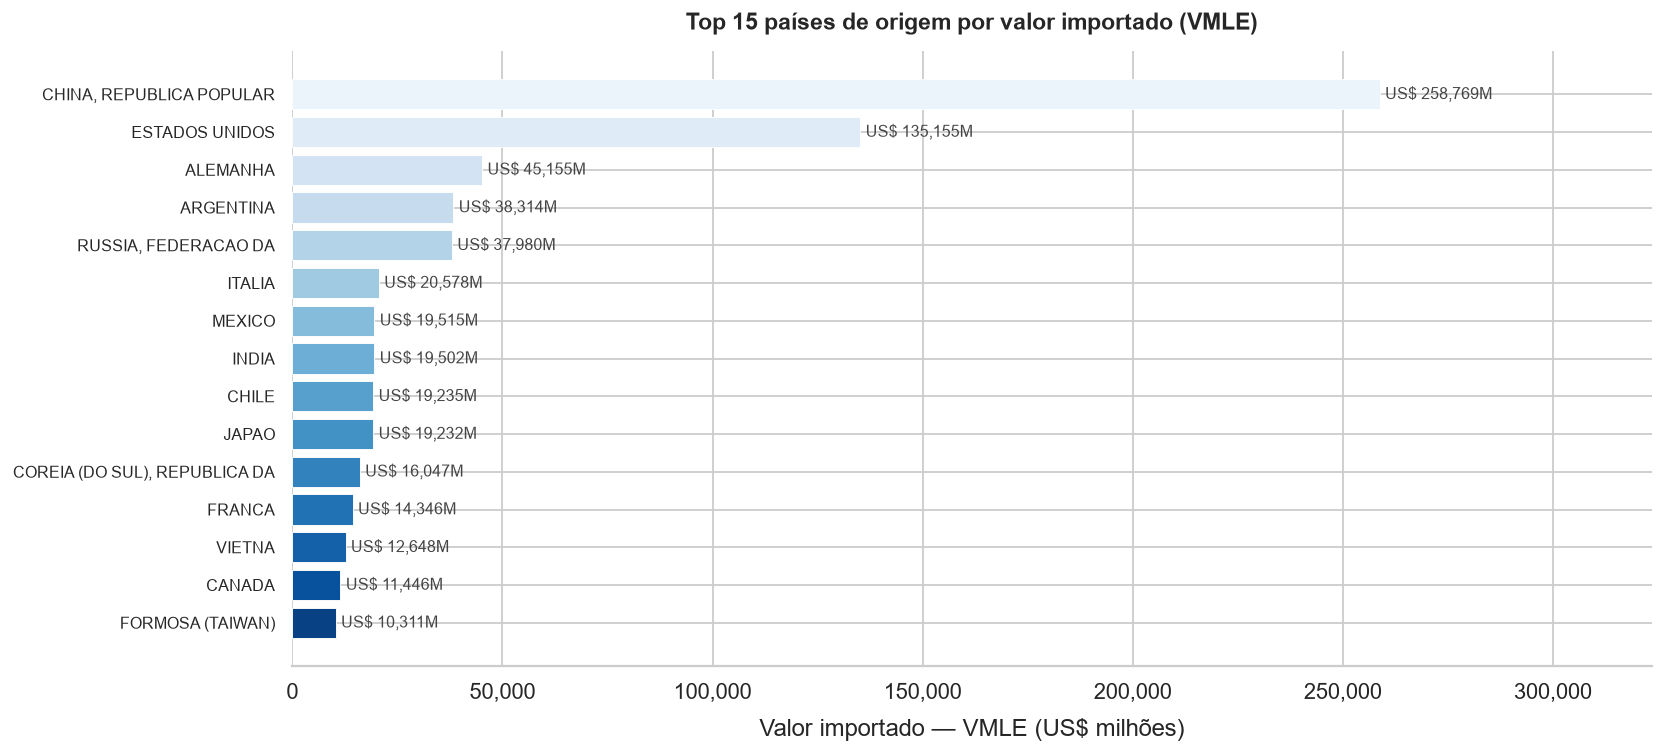

In [14]:
N_PAISES = 15

top_paises = (
    df.groupby('pais_origem')['vmle_soma_dolar_truncado']
    .sum()
    .nlargest(N_PAISES)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(13, 6))

bars = ax.barh(
    top_paises.index,
    top_paises.values / 1e6,
    color=sns.color_palette('Blues_r', N_PAISES),
    edgecolor='white',
    linewidth=0.5,
)

# Rótulo de valor em cada barra
for bar, val in zip(bars, top_paises.values):
    ax.text(
        bar.get_width() + top_paises.max() * 0.005 / 1e6,
        bar.get_y() + bar.get_height() / 2,
        f'US$ {val/1e6:,.0f}M',
        va='center', ha='left', fontsize=9, color='#444'
    )

ax.set_xlabel('Valor importado — VMLE (US$ milhões)', labelpad=8)
ax.set_title(
    f'Top {N_PAISES} países de origem por valor importado (VMLE)',
    fontsize=13, fontweight='bold', pad=12
)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.set_xlim(0, top_paises.max() / 1e6 * 1.25)
ax.tick_params(axis='y', labelsize=9)
sns.despine(left=True)
plt.tight_layout()
plt.savefig('images/eda_01_vmle_por_pais.png', bbox_inches='tight')
plt.show()

### Gráfico 2 — Valor importado (VMLE) por capítulo NCM
**Leitura:** quais categorias de produto concentram o valor importado. O capítulo 85 (equipamentos elétricos) e 31 (fertilizantes) costumam liderar.

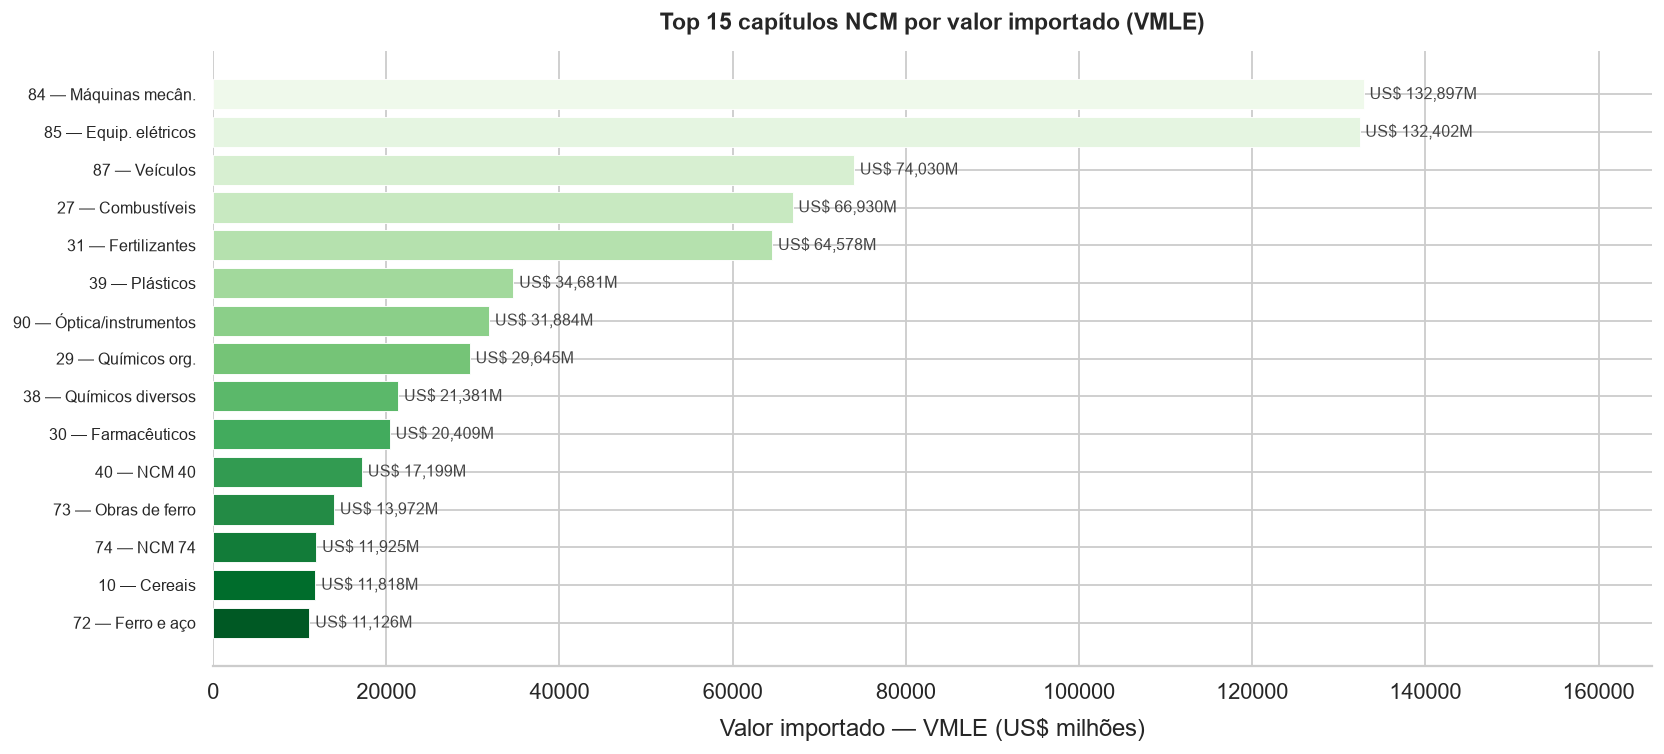

In [15]:
# Descrições resumidas dos capítulos NCM mais comuns
DESC_CAPITULO = {
    '01':'Animais vivos', '02':'Carnes', '03':'Pescados', '04':'Laticínios',
    '10':'Cereais', '12':'Sementes/oleag.', '15':'Gorduras/óleos',
    '27':'Combustíveis', '28':'Químicos inorg.', '29':'Químicos org.',
    '30':'Farmacêuticos', '31':'Fertilizantes', '38':'Químicos diversos',
    '39':'Plásticos', '72':'Ferro e aço', '73':'Obras de ferro',
    '84':'Máquinas mecân.', '85':'Equip. elétricos', '87':'Veículos',
    '88':'Aeronaves', '90':'Óptica/instrumentos', '94':'Móveis',
}

N_CAPS = 15

top_caps = (
    df.groupby('capitulo_ncm')['vmle_soma_dolar_truncado']
    .sum()
    .nlargest(N_CAPS)
    .sort_values()
    .reset_index()
)
top_caps['label'] = top_caps['capitulo_ncm'].apply(
    lambda c: f"{c} — {DESC_CAPITULO.get(c, 'NCM ' + c)}"
)

fig, ax = plt.subplots(figsize=(13, 6))

bars = ax.barh(
    top_caps['label'],
    top_caps['vmle_soma_dolar_truncado'] / 1e6,
    color=sns.color_palette('Greens_r', N_CAPS),
    edgecolor='white',
    linewidth=0.5,
)

for bar, val in zip(bars, top_caps['vmle_soma_dolar_truncado']):
    ax.text(
        bar.get_width() + top_caps['vmle_soma_dolar_truncado'].max() * 0.005 / 1e6,
        bar.get_y() + bar.get_height() / 2,
        f'US$ {val/1e6:,.0f}M',
        va='center', ha='left', fontsize=9, color='#444'
    )

ax.set_xlabel('Valor importado — VMLE (US$ milhões)', labelpad=8)
ax.set_title(
    f'Top {N_CAPS} capítulos NCM por valor importado (VMLE)',
    fontsize=13, fontweight='bold', pad=12
)
ax.set_xlim(0, top_caps['vmle_soma_dolar_truncado'].max() / 1e6 * 1.25)
ax.tick_params(axis='y', labelsize=9)
sns.despine(left=True)
plt.tight_layout()
plt.savefig('images/eda_02_vmle_por_capitulo.png', bbox_inches='tight')
plt.show()

### Gráfico 3 — Distribuição do preço FOB/kg (mediana) por unidade de medida
**Leitura:** dispersão de preço unitário entre diferentes tipos de produto. Escala logarítmica para lidar com a amplitude dos valores (de centavos a centenas de milhares de dólares por kg). Cada ponto é um NCM.

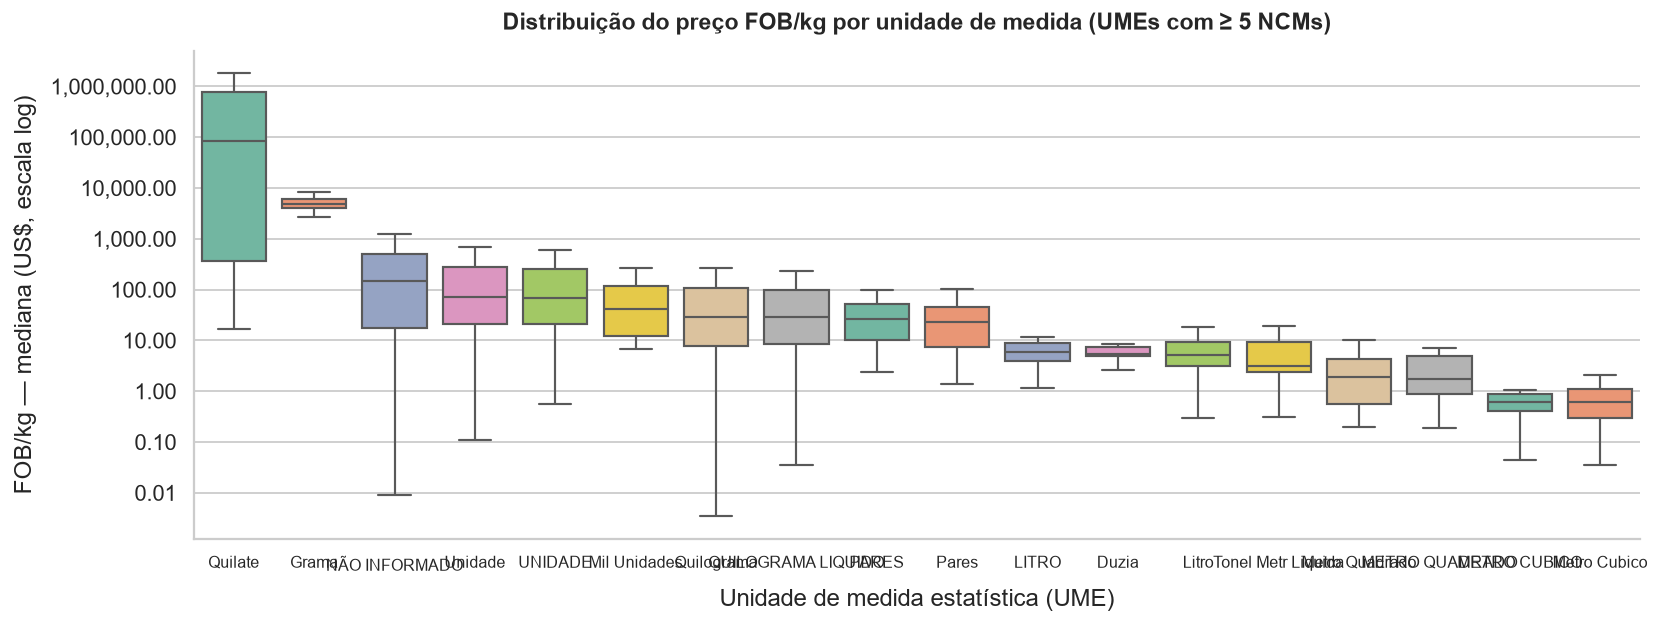

Nota: outliers extremos omitidos. Escala logarítmica no eixo Y.


In [16]:
# Filtra UMEs com ao menos 5 linhas para boxplot representativo
ume_counts  = df['ume'].value_counts()
umes_validas = ume_counts[ume_counts >= 5].index.tolist()

df_box = df[
    df['ume'].isin(umes_validas) &
    df['fob_kg_mediana_dolar_truncado'].notna() &
    (df['fob_kg_mediana_dolar_truncado'] > 0)
].copy()

# Ordena UMEs pela mediana para facilitar leitura
ordem_ume = (
    df_box.groupby('ume')['fob_kg_mediana_dolar_truncado']
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)

fig, ax = plt.subplots(figsize=(13, 5))

sns.boxplot(
    data=df_box,
    x='ume',
    y='fob_kg_mediana_dolar_truncado',
    order=ordem_ume,
    palette='Set2',
    showfliers=False,   # outliers extremos omitidos para melhor visualização
    linewidth=1.2,
    ax=ax,
)

ax.set_yscale('log')
ax.set_ylabel('FOB/kg — mediana (US$, escala log)', labelpad=8)
ax.set_xlabel('Unidade de medida estatística (UME)', labelpad=8)
ax.set_title(
    'Distribuição do preço FOB/kg por unidade de medida (UMEs com ≥ 5 NCMs)',
    fontsize=13, fontweight='bold', pad=12
)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f'{y:,.2f}'))
ax.tick_params(axis='x', labelsize=9)
sns.despine()
plt.tight_layout()
plt.savefig('images/eda_03_fob_kg_por_ume.png', bbox_inches='tight')
plt.show()
print('Nota: outliers extremos omitidos. Escala logarítmica no eixo Y.')

### Gráfico 4 — Dispersão de preço FOB/kg por capítulo NCM (amplitude interquartil)
**Leitura:** capítulos com maior IQR têm mais variação de preço entre operações — indicativo de heterogeneidade de produto, diferentes especificações ou inconsistência de valoração aduaneira. Útil para priorizar onde aprofundar a análise.

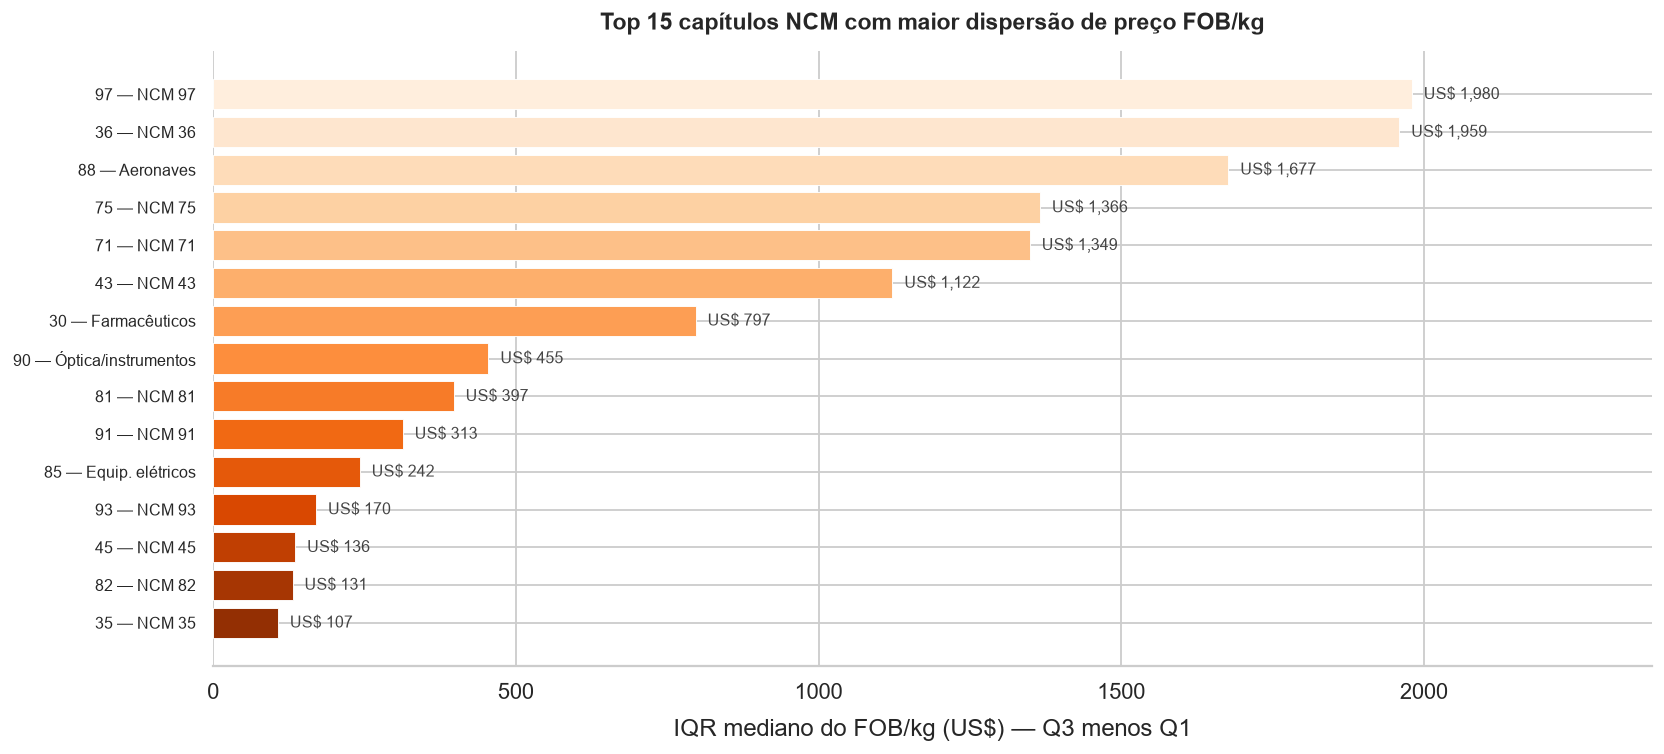

Nota: IQR = Q3 - Q1. Maior IQR = maior variação de preço entre operações do mesmo capítulo.


In [17]:
N_CAPS_IQR = 15

df_iqr = df[
    df['fob_kg_quartil1_truncado'].notna() &
    df['fob_kg_quartil3_truncado'].notna()
].copy()
df_iqr['iqr_fob_kg'] = df_iqr['fob_kg_quartil3_truncado'] - df_iqr['fob_kg_quartil1_truncado']

iqr_por_cap = (
    df_iqr.groupby('capitulo_ncm')['iqr_fob_kg']
    .median()
    .nlargest(N_CAPS_IQR)
    .sort_values()
    .reset_index()
)
iqr_por_cap['label'] = iqr_por_cap['capitulo_ncm'].apply(
    lambda c: f"{c} — {DESC_CAPITULO.get(c, 'NCM ' + c)}"
)

fig, ax = plt.subplots(figsize=(13, 6))

bars = ax.barh(
    iqr_por_cap['label'],
    iqr_por_cap['iqr_fob_kg'],
    color=sns.color_palette('Oranges_r', N_CAPS_IQR),
    edgecolor='white',
    linewidth=0.5,
)

for bar, val in zip(bars, iqr_por_cap['iqr_fob_kg']):
    ax.text(
        bar.get_width() + iqr_por_cap['iqr_fob_kg'].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f'US$ {val:,.0f}',
        va='center', ha='left', fontsize=9, color='#444'
    )

ax.set_xlabel('IQR mediano do FOB/kg (US$) — Q3 menos Q1', labelpad=8)
ax.set_title(
    f'Top {N_CAPS_IQR} capítulos NCM com maior dispersão de preço FOB/kg',
    fontsize=13, fontweight='bold', pad=12
)
ax.set_xlim(0, iqr_por_cap['iqr_fob_kg'].max() * 1.2)
ax.tick_params(axis='y', labelsize=9)
sns.despine(left=True)
plt.tight_layout()
plt.savefig('images/eda_04_dispersao_fob_kg_capitulo.png', bbox_inches='tight')
plt.show()
print('Nota: IQR = Q3 - Q1. Maior IQR = maior variação de preço entre operações do mesmo capítulo.')

---
## 5. Próximos passos sugeridos

Com esses 4 gráficos como ponto de partida, os próximos notebooks de EDA podem explorar:

- **`02_distribuicao_precos.ipynb`** — aprofundar a dispersão de FOB/kg e FOB/UME por NCM e país, comparando medianas entre origens para o mesmo produto.
- **`03_concentracao_origens.ipynb`** — índice HHI por capítulo, razão frete/VMLE por país de origem.
- **`04_cobertura_serie.ipynb`** — ao ter múltiplos meses: linhas que aparecem e somem, contagem de meses por NCM × país, sazonalidade.